<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/decisiontree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Decision_Tree_Dataset.xlsx to Decision_Tree_Dataset.xlsx

TASK 1: LOAD AND UNDERSTAND THE DATASET

First 10 Records:
 Study_Hours_Per_Day  Attendance_Percent  Assignment_Score_Percent  Previous_Marks_Percent Result
                   1                  55                        42                      38   Fail
                   2                  60                        48                      42   Fail
                   2                  68                        55                      45   Fail
                   3                  58                        50                      46   Fail
                   3                  72                        60                      49   Fail
                   4                  65                        62                      52   Fail
                   4                  75                        68                      55   Pass
                   5                  62                        70                      56  

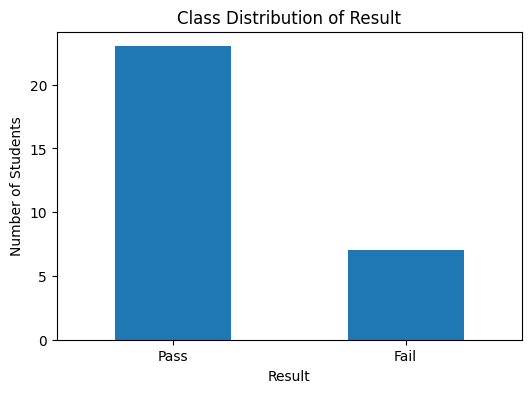


Numerical Features:
['Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score_Percent', 'Previous_Marks_Percent']

Categorical Features:
[]

TASK 2: ENTROPY, GINI IMPURITY AND INFORMATION GAIN

Entropy of Complete Dataset:
0.7838

Gini Impurity of Complete Dataset:
0.3578

Selected Numerical Feature:
Study_Hours_Per_Day

Candidate Split Thresholds and Information Gain:
 Split Threshold  Information Gain
          1.5000            0.0728
          2.5000            0.2391
          3.5000            0.4486
          4.5000            0.4479
          5.5000            0.4900
          6.5000            0.3523
          7.5000            0.2565
          8.5000            0.1825
          9.5000            0.1220
         10.5000            0.0709
         11.5000            0.0266

Best Split Feature:
Study_Hours_Per_Day

Best Split Threshold:
5.5000

Best Information Gain:
0.4900

The best split is selected because it gives the highest Information Gain and produces the largest 

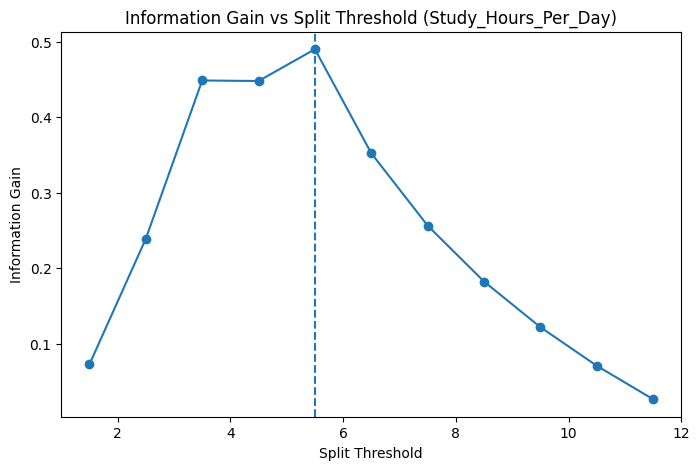


TASK 3: DECISION TREE CONSTRUCTION

Root Node:
Study_Hours_Per_Day <= 5.5000

Left Branch:
Study_Hours_Per_Day <= 5.5000
Number of Records: 10
Class Distribution:
Result
Fail    7
Pass    3

Right Branch:
Study_Hours_Per_Day > 5.5000
Number of Records: 20
Class Distribution:
Result
Pass    20

Leaf Prediction for Left Branch:
Fail

Leaf Prediction for Right Branch:
Pass

Recursive Decision Tree Structure:
The tree continues splitting the subsets until a stopping condition is reached.

Training Decision Tree using Gini Criterion:

Decision Tree Structure:
|--- Assignment_Score_Percent <= 65.00
|   |--- class: Fail
|--- Assignment_Score_Percent >  65.00
|   |--- class: Pass



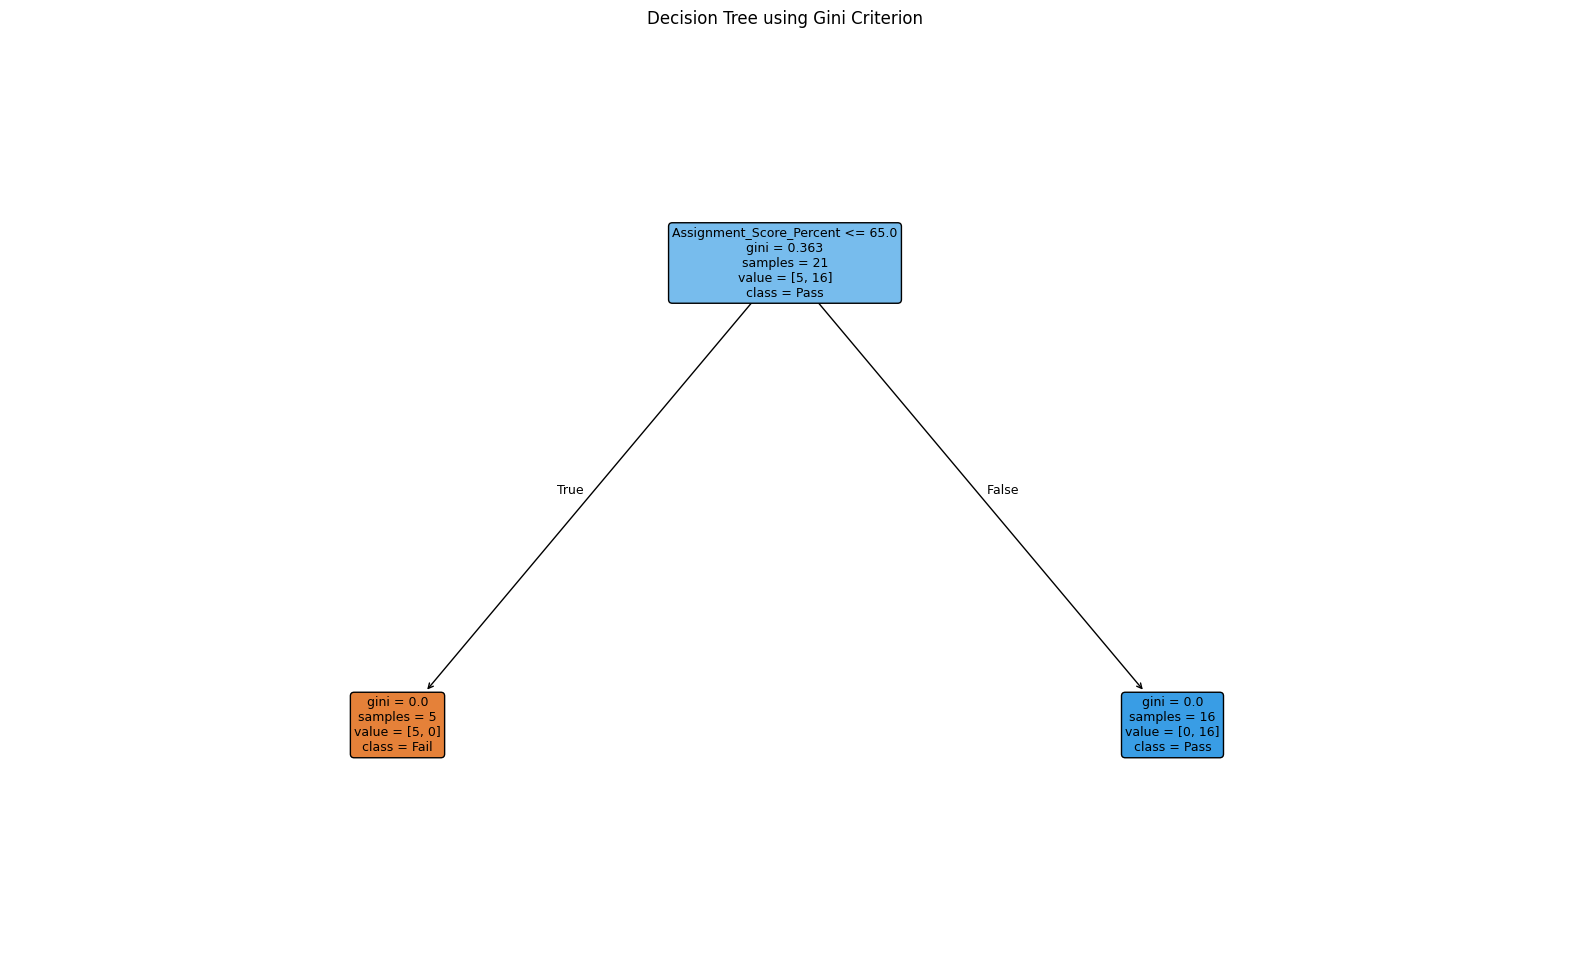


Information Displayed at Each Node:
Each node shows the splitting feature, threshold, impurity, number of samples, class distribution and predicted class.

TASK 4: PREDICTION AND MODEL EVALUATION

Decision Tree Evaluation:
   Metric  Value
 Accuracy 0.8889
Precision 0.8750
   Recall 1.0000
 F1-score 0.9333

Confusion Matrix:
[[1 1]
 [0 7]]


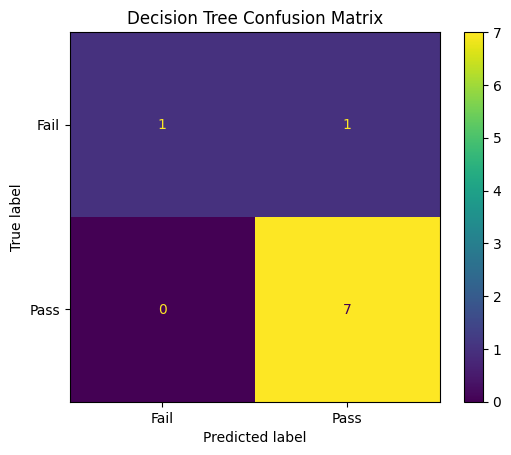


True Positive (TP): 7
True Negative (TN): 1
False Positive (FP): 1
False Negative (FN): 0

TP:
Pass students correctly predicted as Pass.

TN:
Fail students correctly predicted as Fail.

FP:
Fail students incorrectly predicted as Pass.

FN:
Pass students incorrectly predicted as Fail.

TASK 5: FEATURE IMPORTANCE AND TREE COMPLEXITY

Feature Importance:
                 Feature  Importance
Assignment_Score_Percent      1.0000
     Study_Hours_Per_Day      0.0000
      Attendance_Percent      0.0000
  Previous_Marks_Percent      0.0000


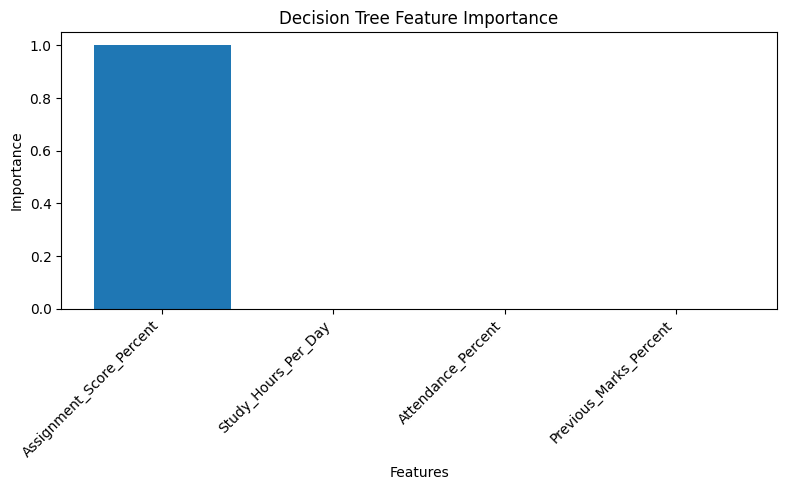


Accuracy for Different Tree Depths:
 Max Depth  Training Accuracy  Testing Accuracy
         1             1.0000            0.8889
         2             1.0000            0.8889
         3             1.0000            0.8889
         4             1.0000            0.8889


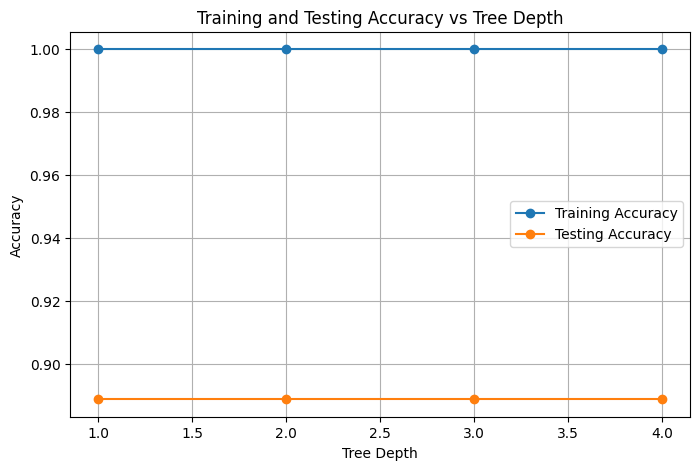


Underfitting and Overfitting:
Underfitting occurs when both training and testing accuracy are low.
Overfitting occurs when training accuracy is very high while testing accuracy is comparatively lower.
A suitable tree depth provides a balance between training and testing performance.

Effect of min_samples_split and min_samples_leaf:
 min_samples_split  min_samples_leaf  Training Accuracy  Testing Accuracy
                 2                 1             1.0000            0.8889
                 5                 2             1.0000            0.8889
                10                 4             1.0000            0.8889

Increasing min_samples_split or min_samples_leaf generally makes the tree simpler and can reduce overfitting.

TASK 6: GINI VS ENTROPY AND NEW PREDICTION

Gini vs Entropy:
          Metric   Gini  Entropy
        Accuracy 0.8889   0.8889
       Precision 0.8750   0.8750
          Recall 1.0000   1.0000
        F1-score 0.9333   0.9333
      Tree Depth 1.0000   1.00

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# TASK 1: LOAD AND UNDERSTAND THE DATASET

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

target = "Result"

print("\n" + "=" * 70)
print("TASK 1: LOAD AND UNDERSTAND THE DATASET")
print("=" * 70)

print("\nFirst 10 Records:")
print(df.head(10).to_string(index=False))

features = [
    col for col in df.columns
    if col != target
]

print("\nInput Features:")
print(features)

print("\nTarget Variable:")
print(target)

print("\nClass Distribution:")
print(df[target].value_counts().to_string())

plt.figure(figsize=(6, 4))

df[target].value_counts().plot(
    kind="bar"
)

plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.title("Class Distribution of Result")
plt.xticks(rotation=0)
plt.show()

numerical_features = df[features].select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = df[features].select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# TASK 2: ENTROPY, GINI IMPURITY AND INFORMATION GAIN

print("\n" + "=" * 70)
print("TASK 2: ENTROPY, GINI IMPURITY AND INFORMATION GAIN")
print("=" * 70)


def calculate_entropy(data):

    probabilities = (
        data[target]
        .value_counts(normalize=True)
    )

    entropy = 0

    for p in probabilities:

        if p > 0:
            entropy -= p * np.log2(p)

    return entropy


def calculate_gini(data):

    probabilities = (
        data[target]
        .value_counts(normalize=True)
    )

    return 1 - np.sum(probabilities ** 2)


def calculate_information_gain(data, feature, threshold):

    left = data[data[feature] <= threshold]

    right = data[data[feature] > threshold]

    if len(left) == 0 or len(right) == 0:
        return 0

    parent_entropy = calculate_entropy(data)

    left_entropy = calculate_entropy(left)
    right_entropy = calculate_entropy(right)

    weighted_entropy = (
        (len(left) / len(data)) * left_entropy
        +
        (len(right) / len(data)) * right_entropy
    )

    information_gain = (
        parent_entropy - weighted_entropy
    )

    return information_gain


complete_entropy = calculate_entropy(df)

complete_gini = calculate_gini(df)

print("\nEntropy of Complete Dataset:")
print(f"{complete_entropy:.4f}")

print("\nGini Impurity of Complete Dataset:")
print(f"{complete_gini:.4f}")


if len(numerical_features) == 0:

    raise ValueError(
        "No numerical feature found in the dataset."
    )

split_feature = numerical_features[0]

print("\nSelected Numerical Feature:")
print(split_feature)

unique_values = np.sort(
    df[split_feature].dropna().unique()
)

candidate_thresholds = (
    unique_values[:-1]
    +
    unique_values[1:]
) / 2

information_gain_values = []

for threshold in candidate_thresholds:

    gain = calculate_information_gain(
        df,
        split_feature,
        threshold
    )

    information_gain_values.append(gain)

information_gain_table = pd.DataFrame({
    "Split Threshold": candidate_thresholds,
    "Information Gain": information_gain_values
})

print("\nCandidate Split Thresholds and Information Gain:")

print(
    information_gain_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_index = np.argmax(
    information_gain_values
)

best_threshold = candidate_thresholds[
    best_index
]

best_information_gain = information_gain_values[
    best_index
]

print("\nBest Split Feature:")
print(split_feature)

print("\nBest Split Threshold:")
print(f"{best_threshold:.4f}")

print("\nBest Information Gain:")
print(f"{best_information_gain:.4f}")

print(
    "\nThe best split is selected because it gives "
    "the highest Information Gain and produces the "
    "largest reduction in entropy."
)

plt.figure(figsize=(8, 5))

plt.plot(
    candidate_thresholds,
    information_gain_values,
    marker="o"
)

plt.axvline(
    best_threshold,
    linestyle="--"
)

plt.xlabel("Split Threshold")
plt.ylabel("Information Gain")
plt.title(
    f"Information Gain vs Split Threshold ({split_feature})"
)

plt.show()


# TASK 3: DECISION TREE CONSTRUCTION

print("\n" + "=" * 70)
print("TASK 3: DECISION TREE CONSTRUCTION")
print("=" * 70)

left_subset = df[
    df[split_feature] <= best_threshold
]

right_subset = df[
    df[split_feature] > best_threshold
]

print("\nRoot Node:")
print(
    f"{split_feature} <= {best_threshold:.4f}"
)

print("\nLeft Branch:")
print(
    f"{split_feature} <= {best_threshold:.4f}"
)

print("Number of Records:", len(left_subset))

print("Class Distribution:")
print(
    left_subset[target]
    .value_counts()
    .to_string()
)

print("\nRight Branch:")
print(
    f"{split_feature} > {best_threshold:.4f}"
)

print("Number of Records:", len(right_subset))

print("Class Distribution:")
print(
    right_subset[target]
    .value_counts()
    .to_string()
)

if len(left_subset) > 0:

    left_prediction = (
        left_subset[target]
        .mode()[0]
    )

else:

    left_prediction = "None"

if len(right_subset) > 0:

    right_prediction = (
        right_subset[target]
        .mode()[0]
    )

else:

    right_prediction = "None"

print("\nLeaf Prediction for Left Branch:")
print(left_prediction)

print("\nLeaf Prediction for Right Branch:")
print(right_prediction)

print("\nRecursive Decision Tree Structure:")

print(
    "The tree continues splitting the subsets "
    "until a stopping condition is reached."
)

print("\nTraining Decision Tree using Gini Criterion:")

X_original = df[features].copy()

X_encoded = X_original.copy()

if len(categorical_features) > 0:

    tree_encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_encoded[categorical_features] = (
        tree_encoder.fit_transform(
            X_original[categorical_features].astype(str)
        )
    )

X = X_encoded
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_tree.fit(
    X_train,
    y_train
)

print("\nDecision Tree Structure:")

tree_text = export_text(
    gini_tree,
    feature_names=list(X.columns)
)

print(tree_text)

plt.figure(figsize=(20, 12))

plot_tree(
    gini_tree,
    feature_names=list(X.columns),
    class_names=[
        str(c)
        for c in gini_tree.classes_
    ],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(
    "Decision Tree using Gini Criterion"
)

plt.show()

print("\nInformation Displayed at Each Node:")

print(
    "Each node shows the splitting feature, "
    "threshold, impurity, number of samples, "
    "class distribution and predicted class."
)


# TASK 4: PREDICTION AND MODEL EVALUATION

print("\n" + "=" * 70)
print("TASK 4: PREDICTION AND MODEL EVALUATION")
print("=" * 70)

gini_predictions = gini_tree.predict(
    X_test
)

accuracy = accuracy_score(
    y_test,
    gini_predictions
)

precision = precision_score(
    y_test,
    gini_predictions,
    pos_label="Pass",
    zero_division=0
)

recall = recall_score(
    y_test,
    gini_predictions,
    pos_label="Pass",
    zero_division=0
)

f1 = f1_score(
    y_test,
    gini_predictions,
    pos_label="Pass",
    zero_division=0
)

evaluation_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print("\nDecision Tree Evaluation:")

print(
    evaluation_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

cm = confusion_matrix(
    y_test,
    gini_predictions,
    labels=gini_tree.classes_
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=gini_tree.classes_
)

disp.plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

if len(gini_tree.classes_) == 2:

    tn, fp, fn, tp = cm.ravel()

    print("\nTrue Positive (TP):", tp)
    print("True Negative (TN):", tn)
    print("False Positive (FP):", fp)
    print("False Negative (FN):", fn)

print("\nTP:")
print(
    "Pass students correctly predicted as Pass."
)

print("\nTN:")
print(
    "Fail students correctly predicted as Fail."
)

print("\nFP:")
print(
    "Fail students incorrectly predicted as Pass."
)

print("\nFN:")
print(
    "Pass students incorrectly predicted as Fail."
)


# TASK 5: FEATURE IMPORTANCE AND TREE COMPLEXITY

print("\n" + "=" * 70)
print("TASK 5: FEATURE IMPORTANCE AND TREE COMPLEXITY")
print("=" * 70)

feature_importance_table = pd.DataFrame({
    "Feature": X.columns,
    "Importance": gini_tree.feature_importances_
})

feature_importance_table = (
    feature_importance_table
    .sort_values(
        by="Importance",
        ascending=False
    )
)

print("\nFeature Importance:")

print(
    feature_importance_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance_table["Feature"],
    feature_importance_table["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Decision Tree Feature Importance")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


depths = range(
    1,
    min(11, gini_tree.get_depth() + 4)
)

training_accuracies = []
testing_accuracies = []

for depth in depths:

    depth_tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    depth_tree.fit(
        X_train,
        y_train
    )

    train_prediction = depth_tree.predict(
        X_train
    )

    test_prediction = depth_tree.predict(
        X_test
    )

    training_accuracies.append(
        accuracy_score(
            y_train,
            train_prediction
        )
    )

    testing_accuracies.append(
        accuracy_score(
            y_test,
            test_prediction
        )
    )

depth_table = pd.DataFrame({
    "Max Depth": list(depths),
    "Training Accuracy": training_accuracies,
    "Testing Accuracy": testing_accuracies
})

print("\nAccuracy for Different Tree Depths:")

print(
    depth_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    training_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    testing_accuracies,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title(
    "Training and Testing Accuracy vs Tree Depth"
)

plt.legend()
plt.grid(True)

plt.show()

print("\nUnderfitting and Overfitting:")

print(
    "Underfitting occurs when both training and testing "
    "accuracy are low."
)

print(
    "Overfitting occurs when training accuracy is very high "
    "while testing accuracy is comparatively lower."
)

print(
    "A suitable tree depth provides a balance between "
    "training and testing performance."
)


complexity_values = [
    (2, 1),
    (5, 2),
    (10, 4)
]

complexity_rows = []

for min_split, min_leaf in complexity_values:

    complexity_tree = DecisionTreeClassifier(
        criterion="gini",
        min_samples_split=min_split,
        min_samples_leaf=min_leaf,
        random_state=42
    )

    complexity_tree.fit(
        X_train,
        y_train
    )

    train_pred = complexity_tree.predict(
        X_train
    )

    test_pred = complexity_tree.predict(
        X_test
    )

    complexity_rows.append({
        "min_samples_split": min_split,
        "min_samples_leaf": min_leaf,
        "Training Accuracy": accuracy_score(
            y_train,
            train_pred
        ),
        "Testing Accuracy": accuracy_score(
            y_test,
            test_pred
        )
    })

complexity_table = pd.DataFrame(
    complexity_rows
)

print("\nEffect of min_samples_split and min_samples_leaf:")

print(
    complexity_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    "\nIncreasing min_samples_split or min_samples_leaf "
    "generally makes the tree simpler and can reduce "
    "overfitting."
)


# TASK 6: GINI VS ENTROPY AND NEW PREDICTION

print("\n" + "=" * 70)
print("TASK 6: GINI VS ENTROPY AND NEW PREDICTION")
print("=" * 70)

entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_tree.fit(
    X_train,
    y_train
)

entropy_predictions = entropy_tree.predict(
    X_test
)

entropy_accuracy = accuracy_score(
    y_test,
    entropy_predictions
)

entropy_precision = precision_score(
    y_test,
    entropy_predictions,
    pos_label="Pass",
    zero_division=0
)

entropy_recall = recall_score(
    y_test,
    entropy_predictions,
    pos_label="Pass",
    zero_division=0
)

entropy_f1 = f1_score(
    y_test,
    entropy_predictions,
    pos_label="Pass",
    zero_division=0
)

criterion_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Tree Depth",
        "Number of Leaves"
    ],
    "Gini": [
        accuracy,
        precision,
        recall,
        f1,
        gini_tree.get_depth(),
        gini_tree.get_n_leaves()
    ],
    "Entropy": [
        entropy_accuracy,
        entropy_precision,
        entropy_recall,
        entropy_f1,
        entropy_tree.get_depth(),
        entropy_tree.get_n_leaves()
    ]
})

print("\nGini vs Entropy:")

print(
    criterion_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nGini Tree Structure:")

print(
    export_text(
        gini_tree,
        feature_names=list(X.columns)
    )
)

print("\nEntropy Tree Structure:")

print(
    export_text(
        entropy_tree,
        feature_names=list(X.columns)
    )
)


new_students = pd.DataFrame()

for feature in features:

    if feature in categorical_features:

        values = (
            df[feature]
            .dropna()
            .astype(str)
            .unique()
        )

        new_students[feature] = [
            df[feature].mode()[0],
            values[0],
            values[-1]
        ]

    else:

        minimum = df[feature].min()
        maximum = df[feature].max()
        mean_value = df[feature].mean()

        new_students[feature] = [
            round(mean_value, 2),
            round(minimum, 2),
            round(maximum, 2)
        ]

new_students = new_students[features]

new_students_encoded = new_students.copy()

if len(categorical_features) > 0:

    new_students_encoded[
        categorical_features
    ] = tree_encoder.transform(
        new_students[
            categorical_features
        ].astype(str)
    )

new_predictions = gini_tree.predict(
    new_students_encoded
)

new_probabilities = gini_tree.predict_proba(
    new_students_encoded
)

prediction_table = new_students.copy()

prediction_table[
    "Predicted Result"
] = new_predictions

for i, c in enumerate(
    gini_tree.classes_
):

    prediction_table[
        f"P({c})"
    ] = new_probabilities[:, i]

print("\nThree New Student Records:")

print(
    new_students.to_string(
        index=False
    )
)

print("\nNew Student Predictions:")

print(
    prediction_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    "\nThe class having the higher predicted "
    "probability is selected as the final prediction."
)